<a href="https://colab.research.google.com/github/contreras-juan/procesamiento_lenguaje_natural/blob/main/Cuadernos/12_Word2Vec_GloVe.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<h1 style="color: #FECB05; text-align: center;">Word2Vec y GloVe</h1>

<h2 style="color: #007ACC;">Autores</h2>

- [Juan Felipe Contreras Alcívar](https://www.linkedin.com/in/juanf-contreras/)

---

<h2 style="color: #007ACC;">Tabla de contenido</h2>

- [<span style="color: #005C99;">Introducción</span>](#introduccion)
- [<span style="color: #005C99;">Word2Vec: CBOW y Skip-gram</span>](#word2vec-cbow-y-skip-gram)
- [<span style="color: #005C99;">Muestreo negativo</span>](#muestreo-negativo)
- [<span style="color: #005C99;">Skip-gram desde cero con Keras</span>](#skip-gram-desde-cero-con-keras)
- [<span style="color: #005C99;">Word2Vec con gensim</span>](#word2vec-con-gensim)
- [<span style="color: #005C99;">GloVe</span>](#glove)
- [<span style="color: #005C99;">Embeddings preentrenados: analogías y evaluación</span>](#embeddings-preentrenados-analogias-y-evaluacion)
- [<span style="color: #005C99;">Sesgos en los embeddings</span>](#sesgos-en-los-embeddings)
- [<span style="color: #005C99;">Embeddings preentrenados en un clasificador</span>](#embeddings-preentrenados-en-un-clasificador)
- [<span style="color: #005C99;">Referencias</span>](#referencias)

---

<h2 style="color: #007ACC;">Instalación de librerías</h2>

Ejecuta esta celda si trabajas en Google Colab o en un entorno nuevo.

In [1]:
# Instalación de librerías necesarias para esta sesión
# (útil en Google Colab o en un entorno nuevo)
%pip install -q numpy pandas matplotlib scikit-learn tensorflow gensim datasets

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"  # oculta mensajes informativos de TensorFlow

import re
import string
import time
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
keras.utils.set_random_seed(SEED)  # fija las semillas de Python, NumPy y TensorFlow

import gensim
import gensim.downloader as api
from gensim.models import Word2Vec
from gensim.test.utils import datapath

<a id="introduccion"></a>
<h2 style="color: #007ACC;">Introducción</h2>

En el cuaderno 11 los embeddings se aprendieron para clasificar sentimiento, y por eso solo capturaron polaridad: *recomiendo* terminó junto a *que* y *un*. Para obtener representaciones de **significado general**, reutilizables en cualquier tarea, necesitamos un objetivo de entrenamiento que:

1. no requiera etiquetas, para poder usar enormes cantidades de texto, y
2. obligue a los vectores a codificar el significado.

La **hipótesis distribucional** (cuaderno 05) sugiere el objetivo: *predecir las palabras que aparecen alrededor de cada palabra*. Si dos palabras aparecen en contextos similares, el modelo tendrá que darles vectores similares para predecir bien esos contextos.

Este cuaderno presenta los dos métodos clásicos:

- **Word2Vec** (Mikolov et al., 2013): una red neuronal superficial que predice contextos.
- **GloVe** (Pennington et al., 2014): una factorización de la matriz de co-ocurrencia global.

Ambos produjeron los primeros embeddings preentrenados ampliamente reutilizados en PLN, el antecedente directo de los modelos preentrenados del módulo 4.

<a id="word2vec-cbow-y-skip-gram"></a>
<h2 style="color: #007ACC;">Word2Vec: CBOW y Skip-gram</h2>

Word2Vec recorre el corpus con una ventana de tamaño $m$ alrededor de cada **palabra central** $w_t$ y define dos tareas:

| Variante | Predice | Ejemplo con *"el ingenioso hidalgo don Quijote"*, central = *hidalgo* |
|----------|---------|------------------------------------------------------------------------|
| **CBOW** (*Continuous Bag of Words*) | la palabra central a partir del promedio de su contexto | {*el, ingenioso, don, Quijote*} → *hidalgo* |
| **Skip-gram** | cada palabra del contexto a partir de la central | *hidalgo* → *el*, *ingenioso*, *don*, *Quijote* |

Skip-gram maximiza la log-verosimilitud de los contextos:

$$J = \frac{1}{T} \sum_{t=1}^{T} \sum_{-m \le j \le m,\, j \ne 0} \log P(w_{t+j} \mid w_t)$$

Cada palabra tiene **dos** vectores: $\mathbf{v}_w$ cuando es central y $\mathbf{u}_w$ cuando es contexto. La probabilidad se modela con un softmax sobre el producto punto:

$$P(o \mid c) = \frac{\exp(\mathbf{u}_o^\top \mathbf{v}_c)}{\sum_{w \in V} \exp(\mathbf{u}_w^\top \mathbf{v}_c)}$$

Al final se usan los vectores $\mathbf{v}$ (o el promedio de $\mathbf{v}$ y $\mathbf{u}$) como embeddings.

CBOW es más rápido y funciona bien con palabras frecuentes; skip-gram suele representar mejor las palabras raras.

<a id="muestreo-negativo"></a>
<h2 style="color: #007ACC;">Muestreo negativo</h2>

El denominador del softmax recorre **todo el vocabulario** (cientos de miles de palabras) para cada par de entrenamiento: demasiado costoso. El **muestreo negativo** reemplaza la predicción multiclase por una tarea **binaria**: distinguir pares (central, contexto) reales de pares inventados.

Para cada par real $(c, o)$ se muestrean $k$ palabras "negativas" $n_1, \dots, n_k$ al azar, y se maximiza:

$$\log \sigma(\mathbf{u}_o^\top \mathbf{v}_c) + \sum_{i=1}^{k} \log \sigma(-\mathbf{u}_{n_i}^\top \mathbf{v}_c)$$

Es decir, una **regresión logística** que empuja el producto punto de los pares reales hacia valores altos y el de los pares aleatorios hacia valores bajos. Dos detalles prácticos:

- Los negativos se muestrean con probabilidad $P(w) \propto \text{frec}(w)^{0.75}$, que da algo más de oportunidad a las palabras raras que la frecuencia pura.
- **Submuestreo de palabras frecuentes:** palabras como *de* o *que* aparecen en casi todas las ventanas y aportan poca información, así que se descartan aleatoriamente con una probabilidad que crece con su frecuencia.

<a id="skip-gram-desde-cero-con-keras"></a>
<h2 style="color: #007ACC;">Skip-gram desde cero con Keras</h2>

Para entender el algoritmo lo implementaremos con Keras sobre un corpus en español: **Don Quijote de la Mancha** (≈380 000 palabras), descargado de Project Gutenberg.

In [3]:
import urllib.request

URL_QUIJOTE = "https://www.gutenberg.org/cache/epub/2000/pg2000.txt"
texto = urllib.request.urlopen(URL_QUIJOTE).read().decode("utf-8")
# Quitamos el encabezado y la licencia de Project Gutenberg
texto = texto[texto.find("*** START OF"):texto.find("*** END OF")]
texto = texto[texto.find("\n") + 1:]

tokens_quijote = re.findall(r"[a-záéíóúüñ]+", texto.lower())
print(f"Tokens: {len(tokens_quijote):,} | Tipos: {len(set(tokens_quijote)):,}")
print(" ".join(tokens_quijote[1000:1040]))

Tokens: 383,637 | Tipos: 22,944
sancho panza y el bachiller sansón carrasco donde sancho panza satisface al bachiller sansón carrasco de sus dudas y preguntas con otros sucesos dignos de saberse y de contarse de la discreta y graciosa plática que pasó entre sancho panza


In [4]:
MIN_FREC = 5
frec = Counter(tokens_quijote)
vocab_q = [w for w, c in frec.most_common() if c >= MIN_FREC]
w2i = {w: i for i, w in enumerate(vocab_q)}
corpus_ids = np.array([w2i[w] for w in tokens_quijote if w in w2i])
conteos = np.array([frec[w] for w in vocab_q], dtype=float)
print(f"Vocabulario (frecuencia >= {MIN_FREC}): {len(vocab_q):,} palabras | tokens usados: {len(corpus_ids):,}")

Vocabulario (frecuencia >= 5): 5,321 palabras | tokens usados: 355,528


Generamos los ejemplos de entrenamiento: pares positivos (central, contexto) con ventana aleatoria de hasta 4 palabras y submuestreo de las palabras frecuentes, más 4 negativos por cada positivo.

In [5]:
def generar_pares(ids, conteos, ventana=4, k_neg=4, t=1e-4, rng=None):
    rng = rng or np.random.default_rng(SEED)
    # Submuestreo (Mikolov et al., 2013): se conserva cada token con probabilidad sqrt(t / f)
    f = conteos / conteos.sum()
    p_conservar = np.minimum(1.0, np.sqrt(t / f[ids]))
    ids = ids[rng.random(len(ids)) < p_conservar]

    centrales, contextos = [], []
    for desplazamiento in range(1, ventana + 1):
        # Ventana dinámica: el contexto a distancia d se usa con probabilidad (ventana - d + 1) / ventana
        usar = rng.random(len(ids) - desplazamiento) < (ventana - desplazamiento + 1) / ventana
        a, b = ids[:-desplazamiento][usar], ids[desplazamiento:][usar]
        centrales += [a, b]
        contextos += [b, a]
    centrales, contextos = np.concatenate(centrales), np.concatenate(contextos)

    # Negativos con probabilidad proporcional a frec^0.75
    p_neg = conteos ** 0.75 / (conteos ** 0.75).sum()
    negativos = rng.choice(len(conteos), size=(len(centrales), k_neg), p=p_neg)

    X_central = np.repeat(centrales, k_neg + 1)
    X_contexto = np.column_stack([contextos, negativos]).ravel()
    y = np.tile([1] + [0] * k_neg, len(centrales))
    return X_central, X_contexto, y


X_c, X_o, y_pares = generar_pares(corpus_ids, conteos)
print(f"Ejemplos de entrenamiento: {len(y_pares):,} ({y_pares.mean():.0%} positivos)")
for c, o, etiqueta in list(zip(X_c, X_o, y_pares))[:10]:
    print(f"  {vocab_q[c]:<12} {vocab_q[o]:<12} {'real' if etiqueta else 'negativo'}")

Ejemplos de entrenamiento: 3,125,270 (20% positivos)


  ingenioso    quijote      real
  ingenioso    me           negativo
  ingenioso    lo           negativo
  ingenioso    o            negativo
  ingenioso    acosado      negativo
  quijote      miguel       real
  quijote      enamorado    negativo
  quijote      estómago     negativo
  quijote      según        negativo
  quijote      este         negativo


El modelo tiene dos tablas de embeddings (central y contexto). Para cada par calcula el producto punto de sus vectores y le aplica una sigmoide:

In [6]:
DIM = 100
entrada_c = keras.Input(shape=(), dtype="int64", name="central")
entrada_o = keras.Input(shape=(), dtype="int64", name="contexto")
v = layers.Embedding(len(vocab_q), DIM, name="emb_central")(entrada_c)
u = layers.Embedding(len(vocab_q), DIM, name="emb_contexto")(entrada_o)
puntaje = layers.Dot(axes=1)([v, u])
salida = layers.Activation("sigmoid")(puntaje)
skipgram = keras.Model([entrada_c, entrada_o], salida)
skipgram.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy")

inicio = time.perf_counter()
for epoca in range(5):
    # Cada época usa un submuestreo y negativos nuevos
    X_c, X_o, y_pares = generar_pares(corpus_ids, conteos, rng=np.random.default_rng(SEED + epoca))
    h = skipgram.fit([X_c, X_o], y_pares, batch_size=2048, epochs=1, shuffle=True, verbose=0)
    print(f"época {epoca + 1}: pérdida = {h.history['loss'][0]:.4f}")
print(f"Entrenado en {time.perf_counter() - inicio:.0f} s")

época 1: pérdida = 0.5295


época 2: pérdida = 0.4895


época 3: pérdida = 0.4828


época 4: pérdida = 0.4744


época 5: pérdida = 0.4673
Entrenado en 17 s


In [7]:
W = skipgram.get_layer("emb_central").get_weights()[0]
W = W / np.linalg.norm(W, axis=1, keepdims=True)


def vecinos_q(palabra, k=8):
    sims = W @ W[w2i[palabra]]
    return ", ".join(vocab_q[i] for i in np.argsort(-sims)[1:k + 1])


for palabra in ["sancho", "dulcinea", "rocinante", "caballero", "escudero", "merced", "dijo", "batalla"]:
    print(f"{palabra:<10} -> {vecinos_q(palabra)}")

sancho     -> panza, dijo, costal, correo, despachó, ronda, respondió, jerónimo
dulcinea   -> toboso, desencantar, par, encantada, princesa, desencanto, señora, aldonza
rocinante  -> caballo, rucio, maltrecho, apearse, echándole, púsose, arzón, jumento
caballero  -> valeroso, mancha, valiente, aventurero, hidalgo, alabado, andante, famoso
escudero   -> asendereado, señor, jerónimo, dijo, quijote, galán, don, panza
merced     -> déjeme, vuesa, vuestra, mire, dígame, suplico, diga, sabrá
dijo       -> respondió, señor, replicó, sancho, eso, amigo, mío, paréceme
batalla    -> pasase, estacada, gallardo, hecha, capitán, descomunal, cayó, religioso


Con solo un libro, el modelo ya agrupa a los personajes, sus títulos y tratamientos (*vuestra merced*, *señor*), verbos de habla (*dijo*, *respondió*) y el vocabulario caballeresco. Los vecinos de *sancho* y *dulcinea* incluyen palabras que suelen acompañarlos en el texto: los embeddings mezclan **similitud** (palabras intercambiables) y **asociación** (palabras que aparecen juntas).

Nuestra implementación es didáctica. En la práctica se usa **gensim**, una implementación optimizada en C con varios hilos.

<a id="word2vec-con-gensim"></a>
<h2 style="color: #007ACC;">Word2Vec con gensim</h2>

Entrenemos Word2Vec con gensim sobre un corpus mayor: las **200 000 reseñas de Amazon en español** del cuaderno 11 (unos 5 millones de palabras). No usamos las etiquetas: Word2Vec solo necesita el texto.

In [8]:
from datasets import load_dataset

resenas = load_dataset("SetFit/amazon_reviews_multi_es")
textos_amazon = resenas["train"]["text"]
oraciones_amazon = [re.findall(r"[a-záéíóúüñ0-9]+", t.lower()) for t in textos_amazon]
print(f"Reseñas: {len(oraciones_amazon):,} | tokens: {sum(map(len, oraciones_amazon)):,}")

inicio = time.perf_counter()
w2v = Word2Vec(oraciones_amazon, vector_size=100, window=5, min_count=5, sg=1, negative=5, epochs=5,
               workers=8, seed=SEED)
print(f"Entrenado en {time.perf_counter() - inicio:.0f} s | vocabulario: {len(w2v.wv):,} palabras")

Reseñas: 200,000 | tokens: 5,568,094


Entrenado en 6 s | vocabulario: 21,433 palabras


In [9]:
for palabra in ["móvil", "batería", "talla", "pantalla", "rápido", "excelente", "horrible", "recomiendo"]:
    print(f"{palabra:<11} -> {', '.join(w for w, _ in w2v.wv.most_similar(palabra, topn=7))}")

móvil       -> teléfono, ipad, movil, dispositivo, terminal, tlf, smartphone
batería     -> bateria, autonomía, carga, descarga, duración, pila, agota
talla       -> xl, xxl, 38, tallaje, tallas, l, 44
pantalla    -> protector, táctil, lcd, cristal, lente, sensibilidad, curva
rápido      -> rapidísimo, rapido, rápidamente, rápida, tardío, rapidisimo, extraordinariamente
excelente   -> inmejorable, insuperable, buena, excepcional, magnífica, magnifica, exelente
horrible    -> fatal, horroroso, pésimo, malisimo, terrible, pesimo, malísimo
recomiendo  -> aconsejo, recomendaría, recomendaria, recomendable, aconsejable, recomendamos, aconsejaría


Comparado con los embeddings del cuaderno 11, que solo capturaban polaridad:

- *móvil*, *pantalla*, *batería* y *talla* tienen ahora vecinos con sentido (sinónimos, marcas, partes de un producto).
- *excelente* y *horrible* tienen vecinos de su misma polaridad, pero también aparecen **antónimos** en sus listas o en posiciones cercanas. Es una propiedad bien conocida de los embeddings distribucionales: los antónimos aparecen en contextos casi idénticos (*"la calidad es excelente / horrible"*), así que sus vectores son parecidos.

In [10]:
print("sim(excelente, horrible) =", round(float(w2v.wv.similarity("excelente", "horrible")), 3))
print("sim(excelente, buenísimo) =", round(float(w2v.wv.similarity("excelente", "buenísimo")), 3))
print("sim(excelente, cable)     =", round(float(w2v.wv.similarity("excelente", "cable")), 3))
print("Intruso en [móvil, tablet, portátil, zapatillas]:", w2v.wv.doesnt_match(["móvil", "tablet", "portátil", "zapatillas"]))

sim(excelente, horrible) = 0.462
sim(excelente, buenísimo) = 0.679
sim(excelente, cable)     = 0.243
Intruso en [móvil, tablet, portátil, zapatillas]: zapatillas


<a id="glove"></a>
<h2 style="color: #007ACC;">GloVe</h2>

**GloVe** (*Global Vectors*) parte de la misma matriz de co-ocurrencia $X$ del cuaderno 05, donde $X_{ij}$ cuenta cuántas veces la palabra $j$ aparece en el contexto de la palabra $i$. Busca vectores tales que su producto punto aproxime el **logaritmo** de esa co-ocurrencia:

$$J = \sum_{i, j} f(X_{ij}) \left( \mathbf{w}_i^\top \tilde{\mathbf{w}}_j + b_i + \tilde{b}_j - \log X_{ij} \right)^2$$

- Es un problema de **mínimos cuadrados ponderados** sobre las celdas no nulas de $X$.
- La función de peso $f(x) = \min\left(1, (x / x_{\max})^{0.75}\right)$ reduce la influencia de las co-ocurrencias muy frecuentes (*de la*) y de las muy raras (ruidosas).
- La motivación: las **razones** de co-ocurrencia codifican significado. Por ejemplo, $P(\text{sólido} \mid \text{hielo}) / P(\text{sólido} \mid \text{vapor})$ es grande, mientras que $P(\text{agua} \mid \text{hielo}) / P(\text{agua} \mid \text{vapor}) \approx 1$. Con un modelo log-bilineal, las razones se convierten en **diferencias de vectores**, lo que explica las analogías.

| | Word2Vec | GloVe | PPMI + SVD (cuaderno 05) |
|---|----------|-------|----------------------------|
| Información usada | Ventanas locales, una a una | Conteos globales de co-ocurrencia | Conteos globales de co-ocurrencia |
| Entrenamiento | Descenso del gradiente estocástico | Mínimos cuadrados ponderados | Factorización exacta |
| Escala | Muy grande (en línea) | Muy grande | Limitada por la memoria de la matriz |

Levy & Goldberg (2014) demostraron que skip-gram con muestreo negativo factoriza implícitamente una matriz de PMI desplazada: los tres métodos están más relacionados de lo que parece.

<a id="embeddings-preentrenados-analogias-y-evaluacion"></a>
<h2 style="color: #007ACC;">Embeddings preentrenados: analogías y evaluación</h2>

Entrenar buenos embeddings requiere miles de millones de palabras. Por eso lo habitual es **descargar embeddings preentrenados**. Usaremos GloVe entrenado con Wikipedia y Gigaword en inglés (400 000 palabras, 100 dimensiones, unos 130 MB), disponible en `gensim.downloader`.

> Para español existen, entre otros, los vectores **fastText** de Common Crawl y Wikipedia (`cc.es.300`, [fasttext.cc](https://fasttext.cc/docs/en/crawl-vectors.html)) y los *Spanish Billion Word Corpus and Embeddings* (SBWCE, Cardellino, 2019). Son archivos de varios GB, así que aquí usamos GloVe en inglés para ilustrar.

In [11]:
glove = api.load("glove-wiki-gigaword-100")
print(f"Vocabulario: {len(glove):,} palabras | dimensión: {glove.vector_size}")
for palabra in ["coffee", "python", "king", "colombia"]:
    print(f"{palabra:<9} -> {', '.join(w for w, _ in glove.most_similar(palabra, topn=6))}")

Vocabulario: 400,000 palabras | dimensión: 100
coffee    -> tea, drinks, beer, cocoa, wine, drink
python    -> monty, php, perl, cleese, flipper, ruby
king      -> prince, queen, son, brother, monarch, throne
colombia  -> ecuador, peru, venezuela, bolivia, guatemala, colombian


**Analogías.** Las relaciones semánticas y sintácticas aparecen como **direcciones** aproximadamente constantes en el espacio. Para resolver *"a es a b como c es a ?"* se busca la palabra más cercana a $\mathbf{b} - \mathbf{a} + \mathbf{c}$ (excluyendo las tres palabras de la consulta):

In [12]:
def analogia(a, b, c, modelo=glove):
    return modelo.most_similar(positive=[b, c], negative=[a], topn=1)[0][0]


for a, b, c in [("man", "king", "woman"), ("france", "paris", "japan"), ("big", "bigger", "small"),
                ("walk", "walked", "swim"), ("spain", "spanish", "germany"), ("good", "better", "bad")]:
    print(f"{a} : {b} :: {c} : {analogia(a, b, c)}")

man : king :: woman : queen
france : paris :: japan : tokyo
big : bigger :: small : larger
walk : walked :: swim : swam
spain : spanish :: germany : german
good : better :: bad : worse


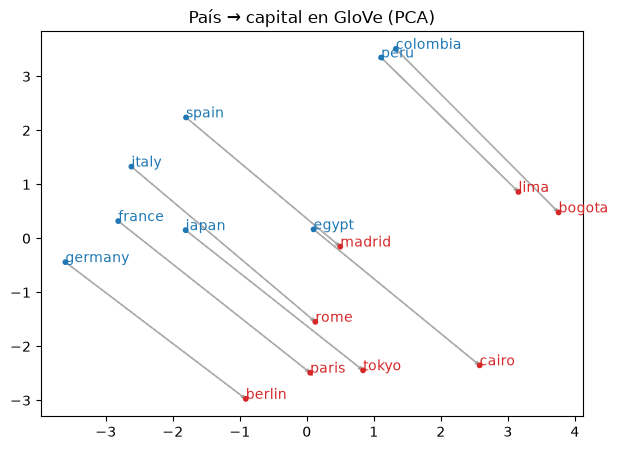

In [13]:
from sklearn.decomposition import PCA

pares = [("spain", "madrid"), ("france", "paris"), ("italy", "rome"), ("germany", "berlin"),
         ("japan", "tokyo"), ("colombia", "bogota"), ("peru", "lima"), ("egypt", "cairo")]
palabras = [w for par in pares for w in par]
P = PCA(n_components=2, random_state=SEED).fit_transform(np.array([glove[w] for w in palabras]))

plt.figure(figsize=(7, 5))
for k, (pais, capital) in enumerate(pares):
    (x1, y1), (x2, y2) = P[2 * k], P[2 * k + 1]
    plt.arrow(x1, y1, x2 - x1, y2 - y1, color="tab:gray", alpha=0.6, length_includes_head=True, head_width=0.05)
    plt.annotate(pais, (x1, y1), color="tab:blue")
    plt.annotate(capital, (x2, y2), color="tab:red")
plt.scatter(P[:, 0], P[:, 1], s=10, c=["tab:blue", "tab:red"] * len(pares))
plt.title("País → capital en GloVe (PCA)")
plt.show()

Las flechas país → capital son aproximadamente **paralelas**: la relación "capital de" corresponde a un desplazamiento similar en el espacio.

**Evaluación intrínseca.** Hay dos pruebas estándar, incluidas en gensim:

- **Analogías de Google** (Mikolov et al., 2013): unas 19 500 analogías semánticas y sintácticas; se mide la exactitud.
- **WordSim-353**: 353 pares de palabras con un puntaje humano de similitud; se mide la correlación de Spearman con la similitud coseno.

Comparemos GloVe con un Word2Vec que entrenamos nosotros sobre **text8** (los primeros 100 MB de Wikipedia en inglés, ≈17 millones de palabras):

In [14]:
from gensim.models.word2vec import Text8Corpus

ruta_text8 = api.load("text8", return_path=True)
inicio = time.perf_counter()
w2v_text8 = Word2Vec(Text8Corpus(ruta_text8), vector_size=100, window=5, min_count=5, sg=1, negative=5,
                     epochs=3, workers=8, seed=SEED)
print(f"Word2Vec sobre text8 entrenado en {time.perf_counter() - inicio:.0f} s")

filas = {}
for nombre, kv in [("Word2Vec (text8, 17M palabras)", w2v_text8.wv), ("GloVe (Wikipedia + Gigaword, 6 000M)", glove)]:
    analogias = kv.evaluate_word_analogies(datapath("questions-words.txt"), restrict_vocab=100_000)[0]
    similitud = kv.evaluate_word_pairs(datapath("wordsim353.tsv"))[1].statistic
    filas[nombre] = {"exactitud en analogías": analogias, "Spearman en WordSim-353": similitud}
pd.DataFrame(filas).T.round(3)

Word2Vec sobre text8 entrenado en 17 s


,exactitud en analogías,Spearman en WordSim-353
"Word2Vec (text8, 17M palabras)",0.229,0.654
"GloVe (Wikipedia + Gigaword, 6 000M)",0.639,0.533


Con unos 350 veces más texto, GloVe gana claramente en analogías, aunque nuestro Word2Vec, entrenado en menos de un minuto, ya captura una parte importante de las relaciones. La cantidad de datos de preentrenamiento es decisiva: es la misma lección que llevará a los grandes modelos del módulo 4.

<a id="sesgos-en-los-embeddings"></a>
<h2 style="color: #007ACC;">Sesgos en los embeddings</h2>

Los embeddings aprenden **todas** las regularidades del texto, incluidos los estereotipos sociales. Bolukbasi et al. (2016) mostraron que la analogía *man : computer_programmer :: woman : ?* devolvía *homemaker* en Word2Vec entrenado con noticias de Google.

Podemos medir el sesgo proyectando palabras sobre una **dirección de género**, por ejemplo $\vec{\text{she}} - \vec{\text{he}}$:

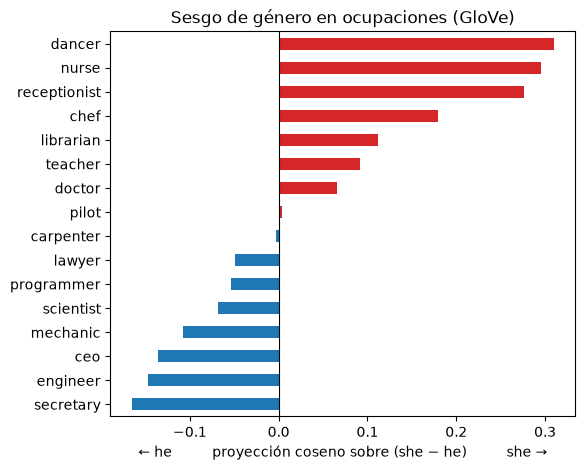

In [15]:
direccion_genero = glove["she"] - glove["he"]
direccion_genero /= np.linalg.norm(direccion_genero)

ocupaciones = ["nurse", "receptionist", "secretary", "teacher", "librarian", "doctor", "lawyer", "scientist",
               "engineer", "programmer", "pilot", "carpenter", "mechanic", "ceo", "dancer", "chef"]
proyecciones = pd.Series({w: float(glove[w] @ direccion_genero / np.linalg.norm(glove[w])) for w in ocupaciones})
proyecciones.sort_values().plot.barh(figsize=(6, 5), color=["tab:blue" if v < 0 else "tab:red" for v in proyecciones.sort_values()])
plt.axvline(0, color="black", lw=0.8)
plt.xlabel("← he          proyección coseno sobre (she − he)          she →")
plt.title("Sesgo de género en ocupaciones (GloVe)")
plt.show()

In [16]:
for a, b, c in [("man", "doctor", "woman"), ("man", "programmer", "woman"), ("he", "brilliant", "she")]:
    print(f"{a} : {b} :: {c} : {[w for w, _ in glove.most_similar(positive=[b, c], negative=[a], topn=3)]}")

man : doctor :: woman : ['nurse', 'physician', 'doctors']
man : programmer :: woman : ['educator', 'programmers', 'linguist']
he : brilliant :: she : ['beautiful', 'gorgeous', 'lovely']


Las ocupaciones se reparten a lo largo del eje de género siguiendo estereotipos presentes en los textos de entrenamiento (*nurse*, *receptionist* hacia *she*; *engineer*, *mechanic*, *carpenter* hacia *he*). Si estos embeddings se usan en un sistema que, por ejemplo, ordena hojas de vida, esos sesgos pueden traducirse en **discriminación**.

Existen técnicas para mitigar el sesgo (por ejemplo, proyectar fuera la dirección de género en las palabras que deberían ser neutras), pero ninguna lo elimina por completo: el sesgo está distribuido en muchas dimensiones (Gonen & Goldberg, 2019). Volveremos sobre esto en el cuaderno 19.

<a id="embeddings-preentrenados-en-un-clasificador"></a>
<h2 style="color: #007ACC;">Embeddings preentrenados en un clasificador</h2>

La utilidad práctica de los embeddings preentrenados aparece cuando hay **pocos datos etiquetados**. Repitamos el clasificador de sentimiento del cuaderno 11, pero con solo **1 000 reseñas etiquetadas**, y comparemos:

1. Embeddings **aleatorios** entrenados desde cero.
2. Embeddings **Word2Vec** (entrenados arriba sobre 200 000 reseñas sin etiquetas) **congelados**.
3. Embeddings Word2Vec como punto de partida, **ajustados** (*fine-tuning*) durante el entrenamiento.

In [17]:
def estandarizar(texto):
    """Minúsculas y eliminación de puntuación, incluidos los signos de apertura del español."""
    texto = tf.strings.lower(texto)
    return tf.strings.regex_replace(texto, r"[¡¿«»“”\"#$%&()*+,\-./:;<=>?@\[\\\]^_`{|}~!']", " ")


def a_binario(split, n=None, semilla=SEED):
    df = resenas[split].to_pandas()
    df = df[df.label != 2]
    if n is not None:
        df = df.sample(n=n, random_state=semilla)
    return df.text.tolist(), (df.label >= 3).astype(int).to_numpy()


X_pocos_txt, y_pocos = a_binario("train", n=1000)
X_val_txt, y_val = a_binario("validation")
X_test_txt, y_test = a_binario("test")

MAX_TOKENS, LONGITUD = 20_000, 100
vectorizador = layers.TextVectorization(max_tokens=MAX_TOKENS, output_sequence_length=LONGITUD, standardize=estandarizar)
vectorizador.adapt(textos_amazon[:60_000])  # el vocabulario puede construirse con texto sin etiquetar
vocab = [str(w) for w in vectorizador.get_vocabulary()]

X_pocos, X_val, X_test = (vectorizador(np.array(t)).numpy() for t in (X_pocos_txt, X_val_txt, X_test_txt))

# Matriz de embeddings inicial: fila i = vector Word2Vec de la palabra i (o ceros si no existe)
matriz_w2v = np.zeros((len(vocab), 100))
cubiertas = 0
for i, w in enumerate(vocab):
    if w in w2v.wv:
        matriz_w2v[i] = w2v.wv[w]
        cubiertas += 1
print(f"Palabras del vocabulario con vector Word2Vec: {cubiertas / len(vocab):.1%}")

Palabras del vocabulario con vector Word2Vec: 85.2%


In [18]:
def clasificador(inicial=None, entrenable=True):
    emb = layers.Embedding(len(vocab), 100, mask_zero=True, trainable=entrenable,
                           embeddings_initializer=keras.initializers.Constant(inicial) if inicial is not None else "uniform")
    modelo = keras.Sequential([keras.Input(shape=(LONGITUD,), dtype="int64"), emb,
                               layers.GlobalAveragePooling1D(), layers.Dense(16, activation="relu"),
                               layers.Dense(1, activation="sigmoid")])
    modelo.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    return modelo


configuraciones = {
    "aleatorios": dict(),
    "Word2Vec congelados": dict(inicial=matriz_w2v, entrenable=False),
    "Word2Vec + fine-tuning": dict(inicial=matriz_w2v, entrenable=True),
}
resultados = {}
for nombre, kw in configuraciones.items():
    keras.utils.set_random_seed(SEED)
    modelo = clasificador(**kw)
    modelo.fit(X_pocos, y_pocos, validation_data=(X_val, y_val), epochs=40, batch_size=32, verbose=0,
               callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)])
    resultados[nombre] = modelo.evaluate(X_test, y_test, verbose=0)[1]

pd.Series(resultados, name="exactitud en prueba (1 000 ejemplos de entrenamiento)").round(4).to_frame()

,exactitud en prueba (1 000 ejemplos de entrenamiento)
aleatorios,0.8105
Word2Vec congelados,0.8278
Word2Vec + fine-tuning,0.8265


Con solo 1 000 ejemplos, los embeddings aleatorios tienen que aprender el significado de miles de palabras a partir de muy poca señal. Los embeddings Word2Vec llegan con ese conocimiento ya incorporado, aprendido de texto **sin etiquetar**, y el clasificador solo tiene que aprender a combinarlo. Esta idea de **preentrenar con mucho texto y luego adaptar con pocos ejemplos** es el núcleo del aprendizaje por transferencia en PLN, y la llevaremos mucho más lejos con BERT y GPT en el módulo 4.

**Limitación fundamental de Word2Vec y GloVe:** asignan **un único vector por palabra**, sin importar el contexto. *Banco* tiene el mismo vector en *"me senté en el banco"* y en *"abrí una cuenta en el banco"*. Los modelos secuenciales del siguiente cuaderno empiezan a resolver esto: procesan la oración palabra por palabra y construyen representaciones que dependen del contexto.

<a id="referencias"></a>
<h2 style="color: #007ACC;">Referencias</h2>

- Jurafsky, D. & Martin, J. H. *Speech and Language Processing* (3.ª ed. borrador). [web.stanford.edu/~jurafsky/slp3](https://web.stanford.edu/~jurafsky/slp3/)
- Lane, H., Howard, C. & Hapke, H. (2019). *Natural Language Processing in Action*. Manning.
- Mikolov, T., Chen, K., Corrado, G. & Dean, J. (2013). Efficient Estimation of Word Representations in Vector Space. *ICLR Workshop*.
- Mikolov, T. et al. (2013). Distributed Representations of Words and Phrases and their Compositionality. *NeurIPS*.
- Pennington, J., Socher, R. & Manning, C. D. (2014). GloVe: Global Vectors for Word Representation. *EMNLP*.
- Levy, O. & Goldberg, Y. (2014). Neural Word Embedding as Implicit Matrix Factorization. *NeurIPS*.
- Bolukbasi, T. et al. (2016). Man is to Computer Programmer as Woman is to Homemaker? Debiasing Word Embeddings. *NeurIPS*.
- Gonen, H. & Goldberg, Y. (2019). Lipstick on a Pig: Debiasing Methods Cover up Systematic Gender Biases in Word Embeddings But do not Remove Them. *NAACL*.